# FMA Project - Variant B: Dynamic Asset Allocation



**Financial Markets Analytics - exam of 22/09/2026**

*mat. 895982 - c.meloni6@campus.unimib.it*



## Research question 
*During the difficult post-2020 years (i.e., the 2020 pandemic crash and the 2022 energy shock linked to the war in Ukraine) which portfolio optimization approach delivers the most robust risk-adjusted allocation: classical Markowitz, Michaud resampling or Black Litterman ? And to what extent do they beat the naive 60/40 and 1/N benchmarks?*


## Abstract 
This project studies dynamic asset allocation on a universe of 19 multi-asset ETFs from 2008 to 2026, with a monthly out-of-sample backtest from 2013 and an estimation window of 60 months. It compares classical Markowitz optimisation (maximum Sharpe and minimum variance), Michaud resampling and a Black-Litterman model with a defensive view activated by volatility, against the 1/N and 60/40 benchmarks.

Over the entire sample Max-Sharpe obtains the highest Sharpe ratio (0.77), followed by Black-Litterman (0.69) and Michaud (0.64); all three are superior to the benchmarks (0.49 and 0.50). Minimum-Variance coincides with the cash proxy and does not exceed the risk-free rate. The first version of Black-Litterman, with a prior constructed on current capitalisations, arrived at 0.86, but part of this result was due to a look-ahead bias; when the market weights are reconstructed month by month from prices, the Sharpe ratio decreases to 0.69.

The crisis analysis does not indicate an absolute winner. Max-Sharpe and Michaud limit losses by remaining almost entirely in cash, but they construct most of their return only after 2022. Black-Litterman remains invested for the entire period and registers a more profound drawdown in 2022; its view reduces losses in stress phases more than it increases the Sharpe ratio. The 60/40 is the worst portfolio in the 2022 shock, when equities and bonds decreased simultaneously.

## Data download and cleanin

In [ ]:
! pip install yfinance pandas numpy matplotlib



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


### The universe: 19 ETFs, with their category


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
tickers = {
    # Equities
    "SPY": "US large-cap equity",
    "IWM": "US small-cap equity",
    "VGK": "Europe equity",
    "EWJ": "Japan equity",
    "EWA": "Australia equity",
    "VWO": "Emerging markets equity",
    # Government bonds
    "SHY": "US Treasury short (1-3y)",
    "IEF": "US Treasury mid (7-10y)",
    "TLT": "US Treasury long (20y+)",
    "EMB": "EM sovereign debt (USD)",
    "BIL": "Cash proxy",
    # Credit
    "LQD": "US investment-grade credit",
    "HYG": "US high-yield credit",
    # Real assets
    "GLD": "Gold",
    "DBC": "Commodities",
    "VNQ": "US real estate (REIT)",
    "TIP": "Inflation-linked bonds",
    "XLE": "Energy sector",
    "SLV": "Silver",
   
}
ticker_list = list(tickers.keys())

###  Download adjusted prices (full available history)


Download the full available price history from Yahoo Finance. I use `auto_adjust=True`
to get *adjusted* prices (already corrected for dividends and splits); without this, returns
would be distorted. I keep only the closing-price column.

In [ ]:
raw = yf.download(ticker_list, period="max", auto_adjust=True, progress=False)
prices = raw["Close"] if isinstance(raw.columns, pd.MultiIndex) else raw
prices = prices[ticker_list]
prices.tail()

Ticker,SPY,IWM,VGK,EWJ,EWA,VWO,SHY,IEF,TLT,EMB,BIL,LQD,HYG,GLD,DBC,VNQ,TIP,XLE,SLV
Date,,,,,,,,,,,,,,,,,,,
2026-09-14,758.995239,287.160004,89.008347,97.580002,29.059999,59.496571,81.339996,90.930000,80.930000,93.220001,91.500000,104.300003,78.529999,392.839996,33.150002,94.330002,105.820000,64.529999,56.840000
2026-09-15,755.513916,285.140015,88.739014,96.919998,28.889999,59.107311,81.309998,90.820000,80.709999,92.989998,91.510002,104.279999,78.379997,394.149994,33.680000,94.099998,105.790001,65.930000,57.529999
2026-09-16,752.182190,283.920013,88.409836,97.010002,28.490000,59.067387,81.239998,90.730003,80.879997,93.059998,91.510002,104.449997,78.419998,391.739990,33.160000,93.480003,105.389999,64.029999,57.049999
2026-09-17,760.710999,285.429993,89.148003,97.910004,29.129999,59.795998,81.360001,91.250000,81.779999,93.660004,91.529999,105.160004,78.720001,398.359985,33.049999,93.809998,105.709999,64.480003,58.970001
2026-09-18,761.690002,284.100006,88.209999,97.000000,28.750000,60.009998,81.239998,90.800003,81.250000,93.379997,91.550003,104.699997,78.529999,401.170013,32.930000,92.910004,105.269997,64.309998,59.930000


Check when each ETF starts. The youngest one sets the **common start**: the backtest can
only begin once *all* assets have data. I trim the series to that date.

In [ ]:
start = prices.apply(lambda col: col.first_valid_index())
for t in ticker_list:
    print(f"{t:5s} {tickers[t]:30s} -> {start[t].date()}")

common_start = start.max()
print(f"\nCommon start (all present): {common_start.date()}")

prices = prices[prices.index >= common_start]

SPY   US large-cap equity            -> 1993-01-29
IWM   US small-cap equity            -> 2000-05-26
VGK   Europe equity                  -> 2005-03-10
EWJ   Japan equity                   -> 1996-03-18
EWA   Australia equity               -> 1996-03-18
VWO   Emerging markets equity        -> 2005-03-10
SHY   US Treasury short (1-3y)       -> 2002-07-30
IEF   US Treasury mid (7-10y)        -> 2002-07-30
TLT   US Treasury long (20y+)        -> 2002-07-30
EMB   EM sovereign debt (USD)        -> 2007-12-19
BIL   Cash proxy                     -> 2007-05-30
LQD   US investment-grade credit     -> 2002-07-30
HYG   US high-yield credit           -> 2007-04-11
GLD   Gold                           -> 2004-11-18
DBC   Commodities                    -> 2006-02-06
VNQ   US real estate (REIT)          -> 2004-09-29
TIP   Inflation-linked bonds         -> 2003-12-05
XLE   Energy sector                  -> 1998-12-22
SLV   Silver                         -> 2006-04-28

Common start (all present): 20

### Pre-processing: missing values


Look for missing values. I fill isolated gaps with the last valid price (`ffill`) and
drop any still-incomplete rows.

In [ ]:
missing = prices.isna().sum()
print("Missing values per ETF:")
print(missing[missing > 0] if missing.sum() > 0 else "none")

prices = prices.ffill().dropna()

Missing values per ETF:
none


###  Monthly log returns


- **Monthly (not daily):** daily data carry microstructure noise that destabilizes the estimates of return and risk; 18.7 years give 224 monthly observations, and monthly annualization (mean ×12, vol ×√12) is more reliable.
- **Log returns:** additive over time (multi-month return = sum of monthly ones), symmetric (+x% and −x% cancel), and closer to normality (prices are ~log-normal → log returns ~normal), fitting Markowitz's mean-variance assumptions. *Caveat:* log returns are not exactly additive across assets, so w'μ is exact only with simple returns; at monthly frequency the difference is second-order and negligible.


In [ ]:
monthly_prices = prices.resample("ME").last()

# monthly log returns  
returns = np.log(monthly_prices / monthly_prices.shift(1)).dropna()

# drop current month if still incomplete
today = pd.Timestamp.today()
if returns.index[-1].month == today.month and returns.index[-1].year == today.year:
    returns = returns.iloc[:-1]
    monthly_prices = monthly_prices.iloc[:-1]

print(f"Months: {len(returns)} ({returns.index.min().date()} -> {returns.index.max().date()})")
print(f"Years of history: {len(returns)/12:.1f}")
returns.head()

Months: 224 (2008-01-31 -> 2026-08-31)
Years of history: 18.7


Ticker,SPY,IWM,VGK,EWJ,EWA,VWO,SHY,IEF,TLT,EMB,BIL,LQD,HYG,GLD,DBC,VNQ,TIP,XLE,SLV
Date,,,,,,,,,,,,,,,,,,,
2008-01-31,-0.062366,-0.067583,-0.094108,-0.043836,-0.069687,-0.094553,0.016411,0.033009,0.020742,0.009427,0.003923,0.025334,-0.018438,0.102932,0.028734,-0.007840,0.035104,-0.131104,0.134806
2008-02-29,-0.026182,-0.029758,-0.002941,-0.015050,-0.012729,0.028364,0.010280,0.012317,-0.004564,-0.004074,0.001634,-0.007087,-0.018870,0.050976,0.105668,-0.032331,0.014126,0.088627,0.156543
2008-03-31,-0.008983,-0.006681,0.013022,-0.012852,-0.029830,-0.037469,0.002532,0.013284,0.021164,0.000930,0.002331,-0.005990,0.009416,-0.061867,-0.009183,0.062837,-0.001400,-0.023640,-0.143371
2008-04-30,0.046561,0.044535,0.040177,0.070985,0.075494,0.080967,-0.008410,-0.024471,-0.025178,0.011550,-0.000654,0.012371,0.033405,-0.042478,0.058633,0.061840,-0.014096,0.098790,-0.019017
2008-05-31,0.015004,0.044780,0.006680,0.019389,0.052247,0.017692,-0.003467,-0.017935,-0.027250,0.001046,0.000960,-0.022298,-0.005098,0.009190,0.066793,-0.002111,0.001068,0.050682,-0.002815


## Risk-free rate (FRED T-Bill) 

The risk-free rate is the return with (essentially) no risk — the floor used in the Sharpe ratio. I use the real 3-month US T-Bill (FRED series `TB3MS`)

In [ ]:
# 3-Month US Treasury Bill (TB3MS): monthly, annual % rate, from FRED
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=TB3MS"
rf_raw = pd.read_csv(url)
rf_raw.columns = ["date", "rf"]                      # robust rename by position
rf_raw["date"] = pd.to_datetime(rf_raw["date"])
rf_raw["rf"] = pd.to_numeric(rf_raw["rf"], errors="coerce")
rf_series = rf_raw.set_index("date")["rf"]

# annual % -> monthly decimal, and move to month-end to match our returns
rf_series.index = rf_series.index + pd.offsets.MonthEnd(0)
rf_monthly = (rf_series / 100.0) / 12.0

# align to our return months
rf = rf_monthly.reindex(returns.index).ffill()

print(rf.tail())
print("Missing rf months:", int(rf.isna().sum()))
print(f"rf range (monthly): {rf.min():.5f} -> {rf.max():.5f}")
print(f"rf range (annualized %): {rf.min()*12*100:.2f}% -> {rf.max()*12*100:.2f}%")

Date
2026-04-30    0.003008
2026-05-31    0.003000
2026-06-30    0.003050
2026-07-31    0.003108
2026-08-31    0.003100
Freq: ME, Name: rf, dtype: float64
Missing rf months: 0
rf range (monthly): 0.00001 -> 0.00445
rf range (annualized %): 0.01% -> 5.34%


## Exploraive analysis

### Cumulative performance 
Each ETF rebased to 100, log scale. Shows long-run return dispersion: growth equities compound far above defensive assets.



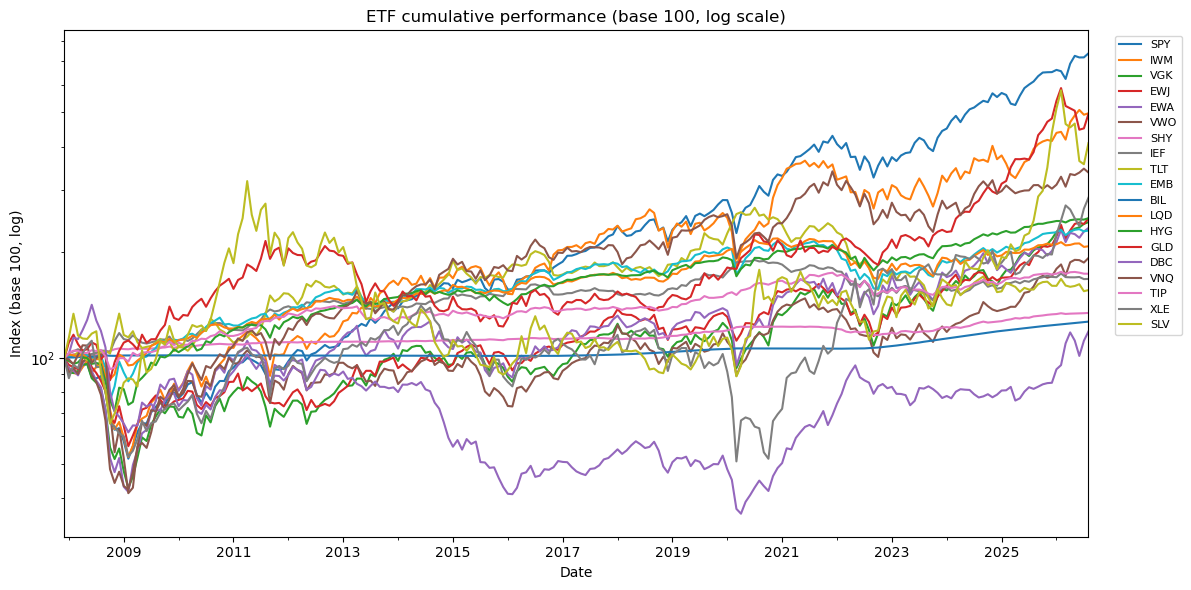

In [ ]:
norm = monthly_prices / monthly_prices.iloc[0] * 100
ax = norm.plot(figsize=(12, 6), logy=True,
               title="ETF cumulative performance (base 100, log scale)")
ax.set_ylabel("Index (base 100, log)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show() 

Each ETF is rebased to 100 and shown on a logarithmic scale, so that equal slopes correspond to equal percentage growth rates. US large-cap equity (SPY) achieves the highest cumulative performance over the full sample, followed by US small-cap equity (IWM) and gold (GLD), while cash and short-term Treasuries (BIL and SHY) remain relatively close to their initial level. Australia (EWA) is the most instructive case: it remains below its initial level for a large part of the sample, showing that an asset can experience a very long recovery period after substantial losses. Silver (SLV) stands out for its large fluctuations, with a wide range of cumulative values that reflects its high volatility. The two major crises also differ in shape: during the 2008–09 financial crisis, most assets experience a broad and simultaneous decline, whereas the 2020 shock is much more abrupt and is followed by a rapid recovery. The chart reflects cumulative return only, not risk; therefore, higher cumulative performance does not necessarily imply better risk-adjusted performance.

### Summary statistics 

Annualized return and volatility, plus skewness and excess kurtosis. High excess kurtosis = fat tails; non-zero skew = asymmetry. Empirical evidence that returns are not exactly normal — a limit of the mean-variance assumption.


In [ ]:
M = 12
summary = pd.DataFrame({
    "Ann. return %": returns.mean() * M * 100,
    "Ann. vol %": returns.std() * np.sqrt(M) * 100,
    "Return/Vol": (returns.mean() * M) / (returns.std() * np.sqrt(M)),
    "Skew": returns.skew(),
    "Excess kurt": returns.kurt(),
}).round(2)
summary.insert(0, "Asset", [tickers[t] for t in summary.index])
summary.sort_values("Ann. vol %")

,Asset,Ann. return %,Ann. vol %,Return/Vol,Skew,Excess kurt
Ticker,,,,,,
BIL,Cash proxy,1.28,0.54,2.37,0.98,-0.30
SHY,US Treasury short (1-3y),1.59,1.45,1.09,0.30,2.16
TIP,Inflation-linked bonds,2.96,5.78,0.51,-0.75,5.04
IEF,US Treasury mid (7-10y),2.78,6.67,0.42,0.12,0.69
LQD,US investment-grade credit,3.93,8.30,0.47,-0.06,5.74
HYG,US high-yield credit,4.91,10.15,0.48,-0.12,7.61
EMB,EM sovereign debt (USD),4.48,11.57,0.39,-1.38,12.37
TLT,US Treasury long (20y+),2.39,14.11,0.17,0.28,1.09
SPY,US large-cap equity,10.70,15.75,0.68,-0.75,1.33


The table is sorted by annualised volatility. Among the riskier assets, SPY has the highest return-to-volatility ratio (0.68), followed by GLD (0.49), HYG (0.48), LQD (0.47) and IWM (0.41). This indicates that US large-cap equity combines relatively high returns with moderate volatility compared with the other risky assets in the universe. The real-asset exposures show a different behaviour: energy (XLE) and silver (SLV) have very high volatility (27.3% and 32.8%) with more modest returns (5.63% and 7.55%), and their possible contribution to diversification depends more on their different return drivers than on their return-to-volatility ratio. The highest value in the entire table, however, belongs to BIL (2.37), not because of a high return but because of an almost zero volatility: this characteristic will have an important role in the behaviour of the optimisers.

### Correlation matrix 
Correlation of monthly returns. Source of diversification: blue (low/negative) pairs move differently and reduce risk; deep red pairs are almost the same bet. Distinct blocks (equities / bonds / real assets) confirm genuine structural diversity.


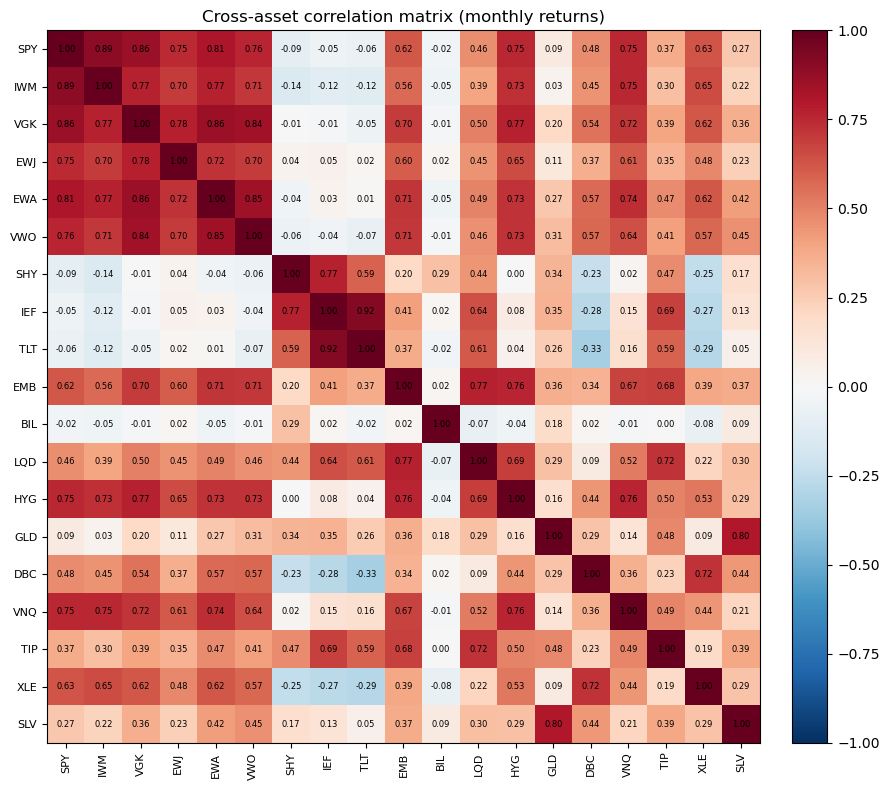

In [ ]:
corr = returns.corr()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.index, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}",
                ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("Cross-asset correlation matrix (monthly returns)")
plt.tight_layout()
plt.show()

A clear block structure emerges. Equities are strongly correlated among themselves (SPY-IWM 0.89, EWA-VGK 0.86, VWO-EWA 0.85), so that holding multiple equity ETFs largely reproduces the same exposure. Government bonds form a separate block (IEF-TLT 0.92). The effective diversifiers are the assets that do not co-move with equities: SHY and TLT are mildly negatively correlated with stocks (SHY-SPY −0.09, TLT-IWM −0.12), while gold and cash are essentially uncorrelated with the rest of the universe (GLD-SPY 0.09, BIL-SPY −0.02). Two features are worth noting. Energy (XLE) is negatively correlated with Treasuries (XLE-TLT −0.29, XLE-IEF −0.27) and thus adds a source of risk absent elsewhere, though it remains an equity exposure (XLE-SPY 0.63). Silver (SLV) is tightly linked to gold (SLV-GLD 0.80) but only loosely to equities, confirming its role as a precious-metal diversifier. It should be stressed that this is the unconditional, full-sample correlation; during crises cross-asset correlations tend to converge toward one, so part of the diversification observed here dissipates precisely when it would be most valuable. This state dependence is examined in the crisis section.

### Return distributions
 Boxplots sorted by volatility. Dots beyond the whiskers are outliers: assets with many (commodities, high yield, equities) have fat tails, confirming non-normality. This is why variance alone underestimates downside risk, and why we also use drawdown later.


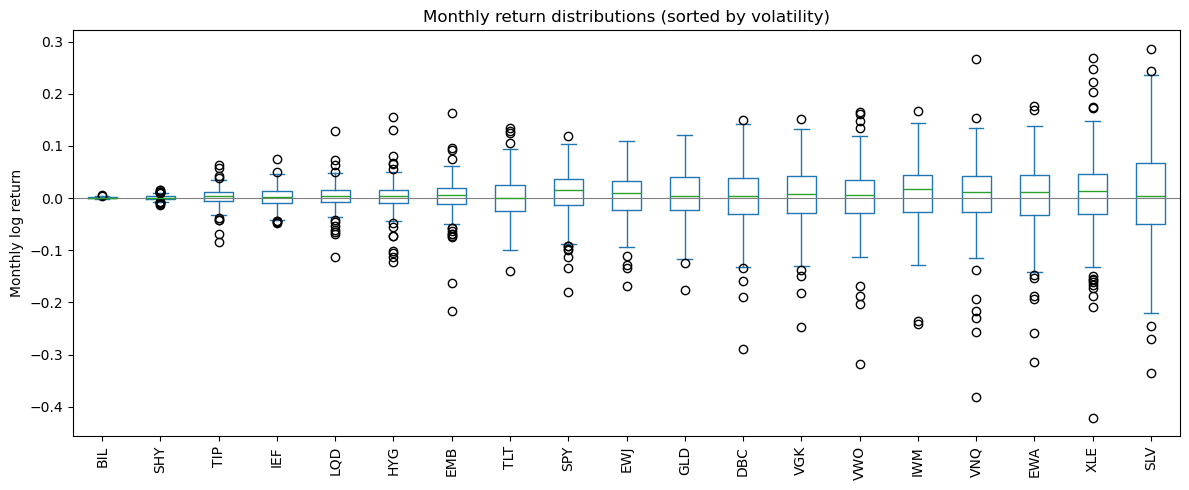

In [ ]:
order = returns.std().sort_values().index
ax = returns[order].plot(kind="box", figsize=(12, 5), rot=90)
ax.set_title("Monthly return distributions (sorted by volatility)")
ax.set_ylabel("Monthly log return")
ax.axhline(0, color="grey", lw=0.8)
plt.tight_layout()
plt.show()

## Markowitz engine: the efficient frontier 
Markowitz does not produce a single portfolio: it produces an entire efficient frontier, a curve of optimal portfolios where each point gives the highest expected return for a given level of risk. What look like different "Markowitz strategies" are simply different points on the same frontier, selected by different criteria: the Global Minimum-Variance (GMV) portfolio is the leftmost point (lowest possible risk), while the Maximum-Sharpe (tangency) portfolio is the point with the best reward-to-risk ratio relative to the risk-free rate. These are not different models, only different choices within one model. By contrast, Markowitz, Michaud and Black-Litterman are genuinely different models: Michaud reduces the estimation-error fragility of mean-variance optimization by resampling, and Black-Litterman replaces the noisy historical means with a market-equilibrium prior adjusted by forward-looking views. From the returns I estimate the annualized expected-return vector μ and covariance matrix Σ, and solve for the weights with scipy SLSQP under a long-only, fully-invested constraint (0 ≤ wᵢ ≤ 1, Σwᵢ = 1). In this project I use two points of the frontier (i.e.,GMV and Max-Sharpe) and then compare Markowitz against the alternative models and the naive benchmarks.


In [ ]:
from scipy.optimize import minimize

MONTHS_PER_YEAR = 12

# --- optimizer building blocks (course-notebook style) ---
def portfolio_variance(w, S):
    return w @ S @ w

def neg_sharpe(w, mu_v, S, rf=0.0):
    return -(w @ mu_v - rf) / np.sqrt(w @ S @ w) # i want to maximize the Sharpe ratio, so I minimize its negative

def solve_min_variance(S, n):
    """Global Minimum-Variance portfolio, long-only, fully invested."""
    w0 = np.ones(n) / n
    cons = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}] # i need the weights to sum to 1, so fully invested
    bnds = [(0, 1)] * n # i want all weights to be between 0 and 1, so no short positions and no leverage
    res = minimize(portfolio_variance, w0, args=(S,), method='SLSQP', # the objective is to minimize the portfolio variance, given the covariance matrix S
                   bounds=bnds, constraints=cons,
                   options={'ftol': 1e-10, 'maxiter': 500})
    return res.x

def solve_max_sharpe(mu_v, S, n, rf=0.0):
    """Tangency (max-Sharpe) portfolio, long-only, fully invested."""
    w0 = np.ones(n) / n
    cons = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]
    bnds = [(0, 1)] * n
    res = minimize(neg_sharpe, w0, args=(mu_v, S, rf), method='SLSQP',
                   bounds=bnds, constraints=cons,
                   options={'ftol': 1e-10, 'maxiter': 500})
    return res.x


### Rolling out-of-sample backtest 
Benchmarks answer the key question: did the optimization actually add value? If a complex model can't beat a naive rule, the complexity isn't justified. I use two. The 1/N (equal-weight) portfolio puts the same weight on all 19 assets. It is simple, but a famously tough benchmark: it has no estimation error at all (no μ, no Σ to get wrong), so it is exactly what fragile optimizers struggle to beat out-of-sample. The 60/40 portfolio holds 60% equities and 40% US government bonds, the canonical balanced allocation — a meaningful reference for stress periods, given the historical flight-to-quality of bonds when equities fall.

Markowitz estimates μ and Σ from past data, so it can concentrate on the assets that looked best in-sample (estimation error). The benchmarks make no estimates: if a model beats them out-of-sample it earned its complexity; if it does not, estimation error outweighed the optimization. This contrast is the core of the project, and it is the same reason the two robust models — Michaud, which reduces estimation error by resampling, and Black-Litterman, which anchors the estimates to a market-equilibrium prior — are expected to narrow the gap. Whether they actually do is the empirical question tested below.


### Benchmark weights

In [ ]:
assets = returns.columns.tolist()
n = len(assets)

# benchmark definitions
equity = ["SPY", "IWM", "VGK", "EWJ", "EWA", "VWO"] # 60% equities: the six equity ETFs, equally weighted among them.
govt   = ["SHY", "IEF", "TLT"] # 40% government bonds: US Treasuries only, across the maturity curve.

def w_1overN():
    w = pd.Series(0.0, index=assets); w[assets] = 1 / len(assets); return w.values

def w_6040():
    w = pd.Series(0.0, index=assets)
    w[equity] = 0.60 / len(equity)
    w[govt]   = 0.40 / len(govt)
    return w.values


In [ ]:
# check: benchmark weights must sum to 1
print("60/40 weights sum:", round(w_6040().sum(), 6))
print("1/N weights sum:", round(w_1overN().sum(), 6))

60/40 weights sum: 1.0
1/N weights sum: 1.0


## Michaud resampling 
Classical mean-variance optimisation treats the estimated μ and Σ as if they were the true parameters, but sample means carry large estimation error; as Michaud (1989) observed, the optimiser then behaves as an "error maximiser", over-allocating to the assets whose returns are most overstated by noise. 

Michaud's Resampled Efficiency (Michaud & Michaud, 2008) addresses this directly by treating the estimates as uncertain. At each rebalancing month I draw B = 100 Monte Carlo samples from N(μ̂, Σ̂); in each simulated world I re-estimate μ and Σ and build the whole efficient frontier over K = 25 points, from minimum variance to maximum return. 

I then average the weights rank by rank across the B worlds, obtaining a single resampled frontier. 

From it I select the portfolio at the max-Sharpe rank, evaluated on the original estimates μ̂, Σ̂ (i.e., the same criterion used for the Markowitz Max-Sharpe strategy), so that the only difference between the two is the resampling itself. 

Averaging rank by rank (rather than averaging max-Sharpe portfolios directly) is the key step: it cancels the lucky-noise bets that dominate a single optimisation and, in principle, yields smoother and more diversified allocations; whether it also yields more stable ones is examined in the results.

In [ ]:
def build_frontier(mu_v, S, n, K=30):
    """Efficient frontier as K portfolios, from minimum variance to maximum return."""
    w_mvp = solve_min_variance(S, n)
    r_mvp = w_mvp @ mu_v
    r_max = mu_v.max() * 0.999
    if r_max <= r_mvp:
        return None
    targets = np.linspace(r_mvp, r_max, K)
    W = np.full((K, n), np.nan)
    w_prev = w_mvp.copy()   # warm start: each point starts from the previous solution
    for k, t in enumerate(targets):
        cons = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1},
                {'type': 'eq', 'fun': lambda w, tt=t: w @ mu_v - tt}]
        res = minimize(portfolio_variance, w_prev, args=(S,),
                       method='SLSQP', bounds=[(0, 1)] * n, constraints=cons,
                       options={'ftol': 1e-8, 'maxiter': 100})
        if res.success:
            W[k] = res.x
            w_prev = res.x
    return W


def michaud_canonical(mu_hat, S_hat, n, rf=0.0, B=100, K=25, T_sim=60, seed=None):
    """
    Canonical Michaud resampling:
    - simulate B worlds from N(mu_hat, S_hat)
    - build the full frontier (K points) in each world
    - average the weights rank by rank -> resampled frontier
    - return the portfolio at the max-Sharpe rank (evaluated on the original estimates)
    """
    if seed is not None:
        np.random.seed(seed)
    mu_m = mu_hat / MONTHS_PER_YEAR
    S_m = S_hat / MONTHS_PER_YEAR

    all_W = np.full((B, K, n), np.nan)
    for b in range(B):
        sim = np.random.multivariate_normal(mu_m, S_m, size=T_sim)
        sim_mu = sim.mean(axis=0) * MONTHS_PER_YEAR
        sim_S = np.cov(sim.T) * MONTHS_PER_YEAR
        Wf = build_frontier(sim_mu, sim_S, n, K)
        if Wf is not None:
            all_W[b] = Wf

    # average rank by rank across the B worlds
    W_res = np.nanmean(all_W, axis=0)
    s = W_res.sum(axis=1, keepdims=True)
    s[s == 0] = 1
    W_res = W_res / s

    # pick the max-Sharpe rank, evaluated on the original estimates
    rets = W_res @ mu_hat
    vols = np.sqrt(np.einsum('ki,ij,kj->k', W_res, S_hat, W_res))
    sharpe = (rets - rf) / vols
    return W_res[np.nanargmax(sharpe)]

## Black-Litterman Model

The Black-Litterman model (Black & Litterman, 1992; He & Litterman, 1999) estimates expected returns by combining two sources of information: the market equilibrium and the investor's views. Its motivation is the same fragility Michaud addresses (i.e., classical mean-variance optimisation is extremely sensitive to the historical means) but the remedy is different: instead of resampling noisy estimates, Black-Litterman replaces them with a neutral, stable starting point.

The model is built from three ingredients, which the model turns from prior into posterior:

- **δ (risk aversion)** — a single number, equal for all assets, derived from the market portfolio itself: δ = (expected market return − rf) / market variance.
- **Π (equilibrium prior)** — the reverse-optimisation step, Π = δΣw_mkt, where w_mkt are the market-capitalisation weights and Σ the covariance matrix. Π is the set of excess returns that would make the observed market portfolio optimal under the CAPM: a prior anchored to a market-cap reality rather than to recent performance, used instead of the historical averages. When no view is active, the function returns Π unchanged and the portfolio stays at equilibrium.
- **Ω (view uncertainty)** — calibrated as in He & Litterman (1999), proportional to the variance of the view portfolio under the prior covariance, P(τΣ)Pᵀ. With this choice only the ratio between Ω and τ enters the model, so the value of τ does not change the posterior.

The views are beliefs about future returns not yet reflected in the market. A Bayesian update combines the prior and the views, each weighted by the inverse of its own uncertainty (τΣ for the prior, Ω for the views): when a view is uncertain the posterior stays close to equilibrium, when it is confident it moves toward the view. Because the views propagate through Σ, a view on one asset automatically adjusts the expected returns of correlated assets, so the portfolio remains internally consistent and diversified without requiring a forecast for every asset.

The resulting posterior μ_BL replaces the historical means and is passed to the same max-Sharpe optimiser used for the other strategies, keeping the comparison controlled. Unlike Markowitz and Michaud, which are purely backward-looking, Black-Litterman can react to a forward-looking scenario that the historical data do not yet contain.

### Market-cap weights as the prior


In [ ]:
# Current ETF assets under management, used as market weights for the Black-Litterman prior
mktcap = {}
for t in ticker_list:
    try:
        info = yf.Ticker(t).info
        mktcap[t] = info.get("totalAssets") or info.get("marketCap")
    except Exception:
        mktcap[t] = None

mktcap = pd.Series(mktcap)
print("Market cap (bn $):\n")
print((mktcap / 1e9).round(1).sort_values(ascending=False))
print(f"\nETFs without data: {mktcap.isna().sum()} out of {len(mktcap)}")

Market cap (bn $):

SPY    811.9
VWO    168.4
GLD    152.9
IWM     80.5
VNQ     70.8
TLT     47.0
BIL     46.8
IEF     41.8
XLE     41.4
VGK     39.1
SLV     34.7
LQD     32.0
SHY     25.9
EWJ     22.7
HYG     16.2
TIP     15.0
EMB     14.9
DBC      1.8
EWA      1.3
dtype: float64

ETFs without data: 0 out of 19


In [ ]:
# historical shares-outstanding of ETFs are not usable to reconstruct time-varying market cap.

rows = []
for t in ticker_list:
    tk = yf.Ticker(t)
    try:
        s = tk.get_shares_full(start="2013-01-01")
        if s is not None and len(s) > 0:
            rows.append({
                "ETF": t,
                "n_oss": len(s),
                "first": s.index.min().date(),
                "last": s.index.max().date(),
            })
        else:
            rows.append({"ETF": t, "n_oss": 0, "first": None, "last": None})
    except Exception as e:
        rows.append({"ETF": t, "n_oss": 0, "first": None, "last": None})

shares_check = pd.DataFrame(rows).set_index("ETF")
print("Availability of historical shares-outstandings:\n")
print(shares_check)
backtest_start = pd.Timestamp("2013-01-01").date()
backtest_end   = pd.Timestamp("2026-08-31").date()
n_total = len(shares_check)
n_empty = (shares_check["n_oss"] == 0).sum()
n_late  = (shares_check["first"] > backtest_start).sum()   
n_early_end = (shares_check["last"] < backtest_end).sum() 

print(f"\n--- syntesis about {n_total} ETF ---")
print(f"without data:            {n_empty}")
print(f"with data starting AFTER 2013:  {n_late}")
print(f"with data ending BEFORE 2026: {n_early_end}")

Availability of historical shares-outstandings:

     n_oss       first        last
ETF                               
SPY    176  2016-05-06  2021-03-17
IWM    168  2016-05-06  2021-03-17
VGK     82  2015-12-30  2021-03-17
EWJ    142  2016-05-04  2021-03-17
EWA    129  2016-05-03  2021-03-17
VWO    113  2016-05-06  2021-03-17
SHY    145  2016-05-06  2021-03-17
IEF    145  2016-05-17  2021-03-17
TLT    155  2016-05-06  2021-03-17
EMB      0        None        None
BIL      0        None        None
LQD    157  2016-05-17  2021-03-17
HYG     14  2019-05-20  2021-03-17
GLD    185  2016-05-06  2021-03-17
DBC     88  2016-02-29  2021-03-17
VNQ    109  2016-05-06  2021-03-17
TIP    167  2016-05-06  2021-03-17
XLE    173  2016-05-06  2021-03-17
SLV    175  2016-05-06  2021-03-17

--- syntesis about 19 ETF ---
without data:            2
with data starting AFTER 2013:  17
with data ending BEFORE 2026: 17


Black-Litterman requires the market weights to construct the prior. I use the current capitalisations of the 19 ETFs, available from Yahoo Finance for all of them (from SPY with 812 billion dollars down to EWA with 1.3 billion), normalised so that their sum is one.

In theory the market weights should vary over time, so I verified whether historical data were available. For the most part they are not: get_shares_full returns nothing for EMB and BIL, and for the other 17 ETFs the series begin around 2015–2016 and stop in March 2021, with interruptions. There are therefore no data for the beginning of the backtest nor for the 2021–2026 period.

In a first version I therefore use a static prior: the current capitalisations, kept fixed for the entire backtest, a choice adopted in the literature when periodic data are missing (Zhao, 2023). This choice, however, introduces a look-ahead bias: today's weights partly reflect the performance realised in the sample, and using them from 2013 gives the model information that was not available at that moment. The problem is quantified and corrected later, with a prior reconstructed month by month from prices. I set τ = 0.025, following He and Litterman (1999).

In [ ]:
w_mkt = (mktcap / mktcap.sum()).reindex(assets).values   # static market prior (current AUM)

TAU = 0.025   # uncertainty of the prior (He & Litterman, 1999)

def black_litterman(mu_hat, S_hat, w_mkt, P, Q, rf=0.0, tau=TAU):
    # risk aversion implied by the market: delta = (w'mu - rf) / (w'Sigma w)
    delta = (w_mkt @ mu_hat - rf) / (w_mkt @ S_hat @ w_mkt)
    # reverse optimisation: implied equilibrium excess returns Pi = delta * Sigma * w_mkt
    Pi = delta * S_hat @ w_mkt
    if P is None or len(P) == 0:
        return Pi + rf

    P = np.atleast_2d(P)
    Q = np.atleast_1d(Q)

    # Omega: uncertainty of the views, proportional to their variance (He & Litterman, 1999)
    Omega = np.diag(np.diag(P @ (tau * S_hat) @ P.T))

    # Bayesian update: posterior expected returns
    tauS_inv = np.linalg.inv(tau * S_hat)
    Omega_inv = np.linalg.inv(Omega)
    mu_BL = np.linalg.inv(tauS_inv + P.T @ Omega_inv @ P) @ \
            (tauS_inv @ Pi + P.T @ Omega_inv @ Q)

    return mu_BL + rf

### The view
The view is relative, not absolute: it states that a defensive basket (GLD and BIL) will return 5% per year more than an equity basket (SPY and IWM), without forecasting the return level of a single asset. The four assets have equal weights in the matrix P (+0.5 for GLD and BIL, −0.5 for SPY and IWM).

The view is activated only in conditions of stress, identified by a volatility signal: when the volatility of SPY over the last 3 months exceeds 1.5 times its volatility over the entire 60-month window. The signal uses only data available up to the month of rebalancing, so it does not introduce look-ahead. The confidence in the view (Ω) follows the calibration of He and Litterman (1999): it is not fixed by hand: the uncertainty of the view grows with the volatility of the assets involved, so the confidence decreases.

In [ ]:
VIEW_SIZE = 0.05   # size of the view: +5% per year

def build_view(win_returns, assets):
    spy = win_returns["SPY"]
    vol_recent = spy.iloc[-3:].std()   # volatility of the last 3 months
    vol_normal = spy.std()             # typical volatility over the whole window

    # stress signal: recent volatility above 1.5x the normal one
    if vol_recent > 1.5 * vol_normal:
        # relative view: (GLD + BIL) outperform (SPY + IWM) by VIEW_SIZE per year
        P = np.zeros((1, len(assets)))
        P[0, assets.index("GLD")] = 0.5    # defensive side (+)
        P[0, assets.index("BIL")] = 0.5
        P[0, assets.index("SPY")] = -0.5   # equity side (-)
        P[0, assets.index("IWM")] = -0.5
        Q = np.array([VIEW_SIZE])
        return P, Q
    return None, None

### The rolling loop
The core of the project. At each month `i` I estimate μ and Σ on the **last 60 months only** (info available up to `i`), compute the weights, and apply them to the **realized return of month `i+1`** — so the month I invest in is never used to estimate (no look-ahead).

**Two return series, on purpose:**
- `returns` (**log**) → to *estimate* μ and Σ (more symmetric, closer to normal).
- `returns_simple` (**simple**) → to *compound realized wealth*: a portfolio's realized return is the weighted average of simple returns (w'R); log returns would add a small bias here (Jensen's inequality). *Log to estimate, simple to compound.*


Backtest: 164 months (2013-01-31 -> 2026-08-31)
Time: 52.3 min
rResults saved to backtest_results.pkl
                 CAGR %  Vol %  Sharpe  MaxDD %
Max-Sharpe         8.31   8.50    0.77   -15.30
Min-Variance       1.70   0.57   -0.16    -0.23
Michaud            6.51   7.50    0.64   -15.02
Black-Litterman   10.25   9.83    0.86   -16.79
1/N                5.95   9.01    0.49   -15.43
60/40              6.15   9.38    0.50   -21.78


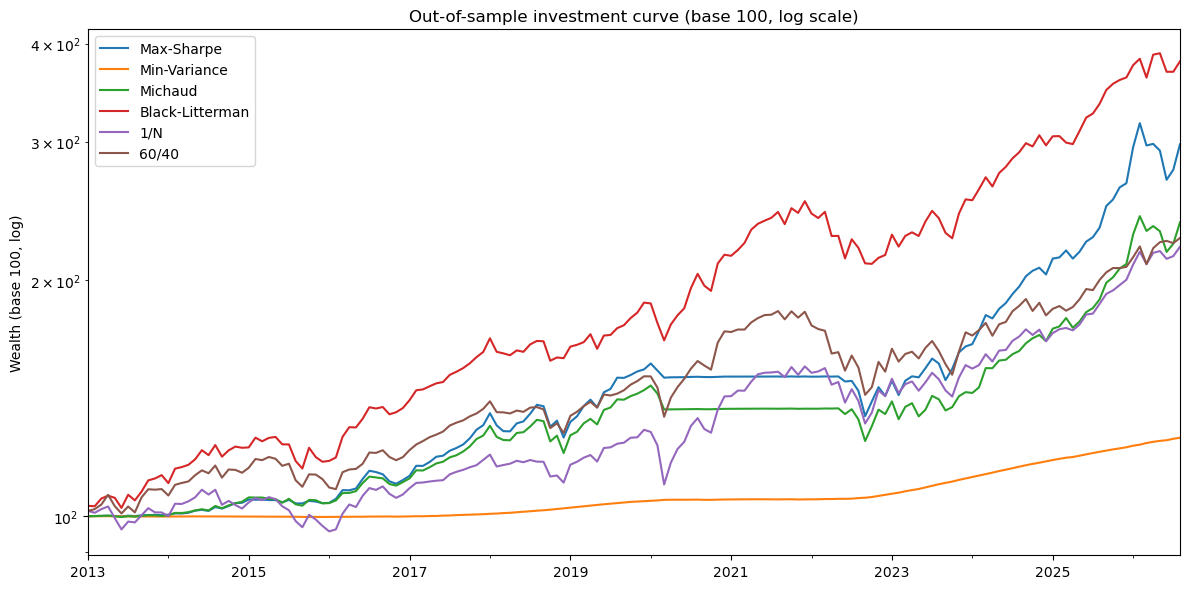

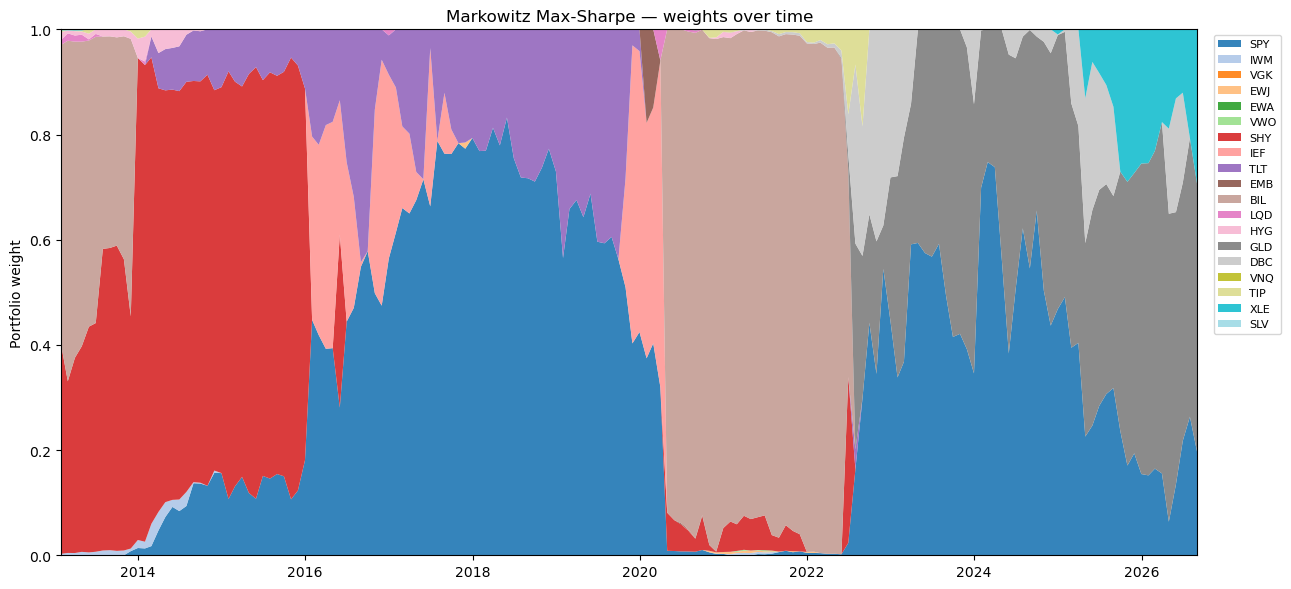

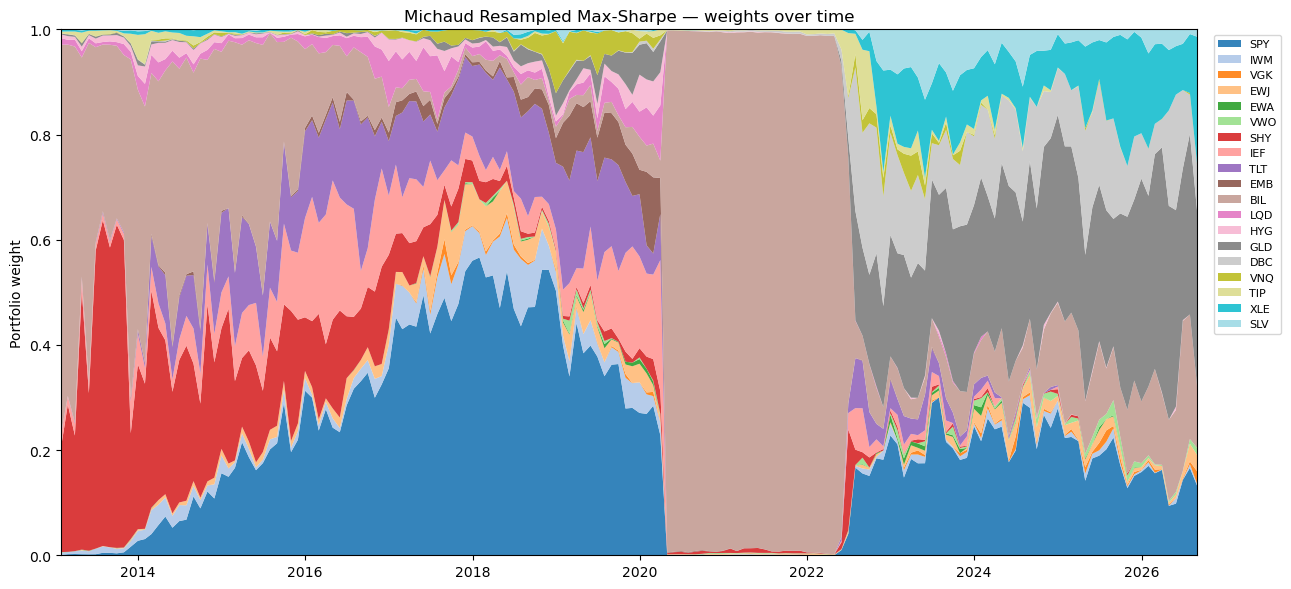

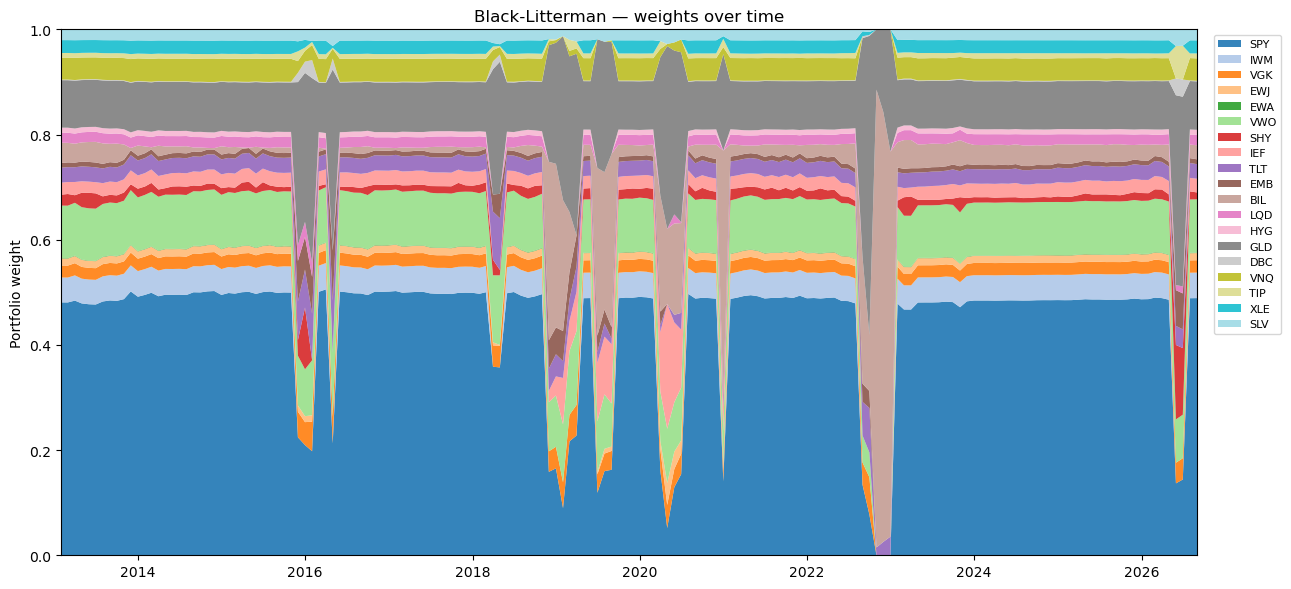

In [ ]:
import time, pickle   
# --- config ---
WINDOW = 60
returns_simple = monthly_prices.pct_change().dropna().reindex(returns.index)

# --- rolling loop ---
dates = returns.index
strategies = ["Max-Sharpe", "Min-Variance", "Michaud", "Black-Litterman", "1/N", "60/40"]
port_rets    = {s: [] for s in strategies}
weights_hist = {s: [] for s in strategies}
rebal_dates  = []

t_start = time.time()                               
for i in range(WINDOW - 1, len(dates) - 1):
    win = returns.iloc[i - WINDOW + 1 : i + 1]
    mu_hat = win.mean().values * MONTHS_PER_YEAR
    S_hat  = win.cov().values  * MONTHS_PER_YEAR
    rf_ann = rf.iloc[i] * MONTHS_PER_YEAR

     # Black-Litterman
    P, Q = build_view(win, assets)
    mu_bl = black_litterman(mu_hat, S_hat, w_mkt, P, Q, rf=rf_ann)
    w_bl = solve_max_sharpe(mu_bl, S_hat, n, rf=rf_ann)

    w = {
        "Max-Sharpe":   solve_max_sharpe(mu_hat, S_hat, n, rf=rf_ann),
        "Min-Variance": solve_min_variance(S_hat, n),
        "Michaud":      michaud_canonical(mu_hat, S_hat, n, rf=rf_ann,
                                          B=100, K=25, T_sim=WINDOW, seed=i), 
        "Black-Litterman": w_bl,
        "1/N":          w_1overN(),
        "60/40":        w_6040(),
        
    }

    r_next = returns_simple.iloc[i + 1].values
    for s in strategies:
        port_rets[s].append(w[s] @ r_next)
        weights_hist[s].append(w[s])
    rebal_dates.append(dates[i + 1])

bt = pd.DataFrame(port_rets, index=rebal_dates)
print(f"Backtest: {len(bt)} months ({bt.index.min().date()} -> {bt.index.max().date()})")
print(f"Time: {(time.time()-t_start)/60:.1f} min")  

with open("backtest_results.pkl", "wb") as f:
    pickle.dump({"bt": bt, "weights_hist": weights_hist,
                 "rebal_dates": rebal_dates, "strategies": strategies}, f)
print("rResults saved to backtest_results.pkl")

bt.head(10)

# PERFORMANCE + INVESTMENT CURVE + WEIGHT MAPS

def perf_stats(r):
    r = r.dropna()
    rfa = rf.reindex(r.index)
    cagr   = (1 + r).prod() ** (12 / len(r)) - 1
    vol    = r.std() * np.sqrt(12)
    sharpe = ((r - rfa).mean() * 12) / (r.std() * np.sqrt(12))
    wealth = (1 + r).cumprod()
    maxdd  = (wealth / wealth.cummax() - 1).min()
    return pd.Series({"CAGR %": cagr * 100, "Vol %": vol * 100,
                      "Sharpe": sharpe, "MaxDD %": maxdd * 100})

table = bt.apply(perf_stats).T.round(2)
print(table)

# investment curve (base 100, log scale)
wealth = (1 + bt).cumprod() * 100
ax = wealth.plot(figsize=(12, 6), logy=True,
                 title="Out-of-sample investment curve (base 100, log scale)")
ax.set_ylabel("Wealth (base 100, log)")
plt.tight_layout()
plt.show()


def plot_weights(strategy, title):
    W = pd.DataFrame(weights_hist[strategy], index=rebal_dates, columns=assets)
    colors = plt.cm.tab20(np.linspace(0, 1, len(assets)))
    fig, ax = plt.subplots(figsize=(13, 6))
    ax.stackplot(W.index, W.T.values, labels=assets, colors=colors, alpha=0.9)
    ax.set_xlim(W.index.min(), W.index.max())
    ax.set_ylim(0, 1)
    ax.set_ylabel("Portfolio weight")
    ax.set_title(title)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
    plt.tight_layout()
    plt.show()


plot_weights("Max-Sharpe", "Markowitz Max-Sharpe — weights over time")
plot_weights("Michaud", "Michaud Resampled Max-Sharpe — weights over time")
plot_weights("Black-Litterman", "Black-Litterman — weights over time")

In [ ]:
# average weights of Min-Variance over the backtest
W_mv = pd.DataFrame(weights_hist["Min-Variance"], index=rebal_dates, columns=assets)
print((W_mv.mean() * 100).round(1).sort_values(ascending=False).head(5))

BIL    98.3
SHY     0.9
DBC     0.4
TIP     0.3
LQD     0.1
dtype: float64


### Investment curve and weight allocation

This is the first backtest, with Black-Litterman in its initial version with a static prior. In this version Black-Litterman obtains the highest Sharpe ratio (0.86), but later it is shown that part of this result is due to a look-ahead bias in the prior. Max-Sharpe and Michaud present a long constant phase from mid-2020 to the end of 2022. Min-Variance is invested on average 98.3% in BIL: it practically coincides with the cash proxy, and its Sharpe ratio is negative (−0.16) because BIL returns slightly less than the risk-free rate due to its fees. It should therefore be read as a lower limit of risk, not as a competing strategy.

**The problem of Markowitz**

The weight map of Max-Sharpe shows the three classic defects of mean-variance optimisation when the parameters are estimated. The first is concentration: for long periods the portfolio is invested in few assets, sometimes in only one. The second is instability: the composition changes abruptly from one phase to another (first short-term government bonds, then SPY with long-term bonds, then almost only BIL, finally SPY and GLD), not because the preferences of the investor change, but because the averages estimated over the last 60 months change. The third is blind confidence in the estimates: the optimiser treats the sample averages as true values, and assigns the largest weight to the asset whose average appears most favourable, even when this advantage is due only to the sample. This is the behaviour that Michaud (1989) called "error maximiser": the optimiser amplifies precisely the estimation errors.

**Michaud**

Michaud was created to correct this problem. Instead of treating the estimates as true, it considers them uncertain: it simulates many scenarios compatible with the estimates, constructs the frontier in each, and averages the portfolios. In normal periods the effect is visible: compared with Max-Sharpe, the allocation of Michaud is distributed over more assets and the dominant blocks are smaller. However, Michaud passes through the same phases as Max-Sharpe, and in the 2020–2022 period it is also invested almost entirely in BIL. Resampling therefore attenuates concentration but does not change the direction of the choices when the initial estimate is distorted. The following section shows why.

**Black-Litterman**

Black-Litterman follows a different logic. It does not start from the historical averages, but from an equilibrium prior constructed on the market portfolio: for this reason it maintains a large and stable share of SPY for the entire period, without abrupt changes of composition. It deviates from equilibrium only in the months when the view is active, moving toward GLD and BIL, and then returns to the initial mix.


### Why do Max-Sharpe and Michaud concentrate on BIL?

In [ ]:
# BIL: 60-month average return used by the optimiser vs current risk-free rate (annual %, yearly averages)
bil_mean = returns["BIL"].rolling(WINDOW).mean() * MONTHS_PER_YEAR * 100
rf_now = rf * MONTHS_PER_YEAR * 100
check = pd.DataFrame({"BIL 60m mean %": bil_mean, "rf %": rf_now}).loc[dates[WINDOW - 1]:dates[-2]]
check["gap %"] = check["BIL 60m mean %"] - check["rf %"]
print(check.groupby(check.index.year).mean().round(2))

      BIL 60m mean %  rf %  gap %
Date                             
2012            0.34  0.07   0.27
2013            0.11  0.06   0.06
2014           -0.04  0.03  -0.07
2015           -0.06  0.05  -0.12
2016           -0.06  0.32  -0.38
2017            0.03  0.93  -0.90
2018            0.28  1.94  -1.66
2019            0.70  2.06  -1.36
2020            0.97  0.36   0.60
2021            0.96  0.04   0.92
2022            0.95  2.02  -1.07
2023            1.41  5.07  -3.66
2024            2.03  4.97  -2.94
2025            2.69  4.07  -1.38
2026            3.29  3.63  -0.34


**The estimation error**

The max-Sharpe portfolio is the tangency portfolio: among all portfolios of risky assets, the one with the best ratio between excess return over the risk-free rate and volatility. A truly riskless asset has zero excess return and zero volatility: combining it with the tangency portfolio moves the investor along the risk-free line, but leaves the Sharpe ratio unchanged. In theory, therefore, including cash in the universe should not change the optimal portfolio.

The optimiser, however, does not see BIL as riskless. It estimates its expected return as the average of the last 60 months and compares it with the risk-free rate of the current month; its estimated volatility is minimal, but not zero. The table shows what happens. After the rate cuts of 2020, the past average of BIL exceeds the current risk-free rate, by 0.60 points in 2020 and by 0.92 in 2021: BIL appears to have a positive excess return. Dividing a small positive excess return by an almost zero volatility gives a very high estimated Sharpe ratio, superior to that of any risky asset, and the optimiser concentrates on BIL. In 2022 the risk-free rate increases rapidly, the average difference becomes negative, and at the end of the year the optimisers abandon BIL. In 2013 the difference is slightly positive, and in the first months the optimisers also hold BIL; from 2014 to 2019 it is negative and BIL is not selected.

This is the problem of Markowitz in its most extreme form: a small error in the estimated average, amplified by a volatility close to zero. The phase in cash is therefore not a defensive decision linked to market risk: it depends on the path of interest rates, and in fact it continues also during the market recovery of 2021.

**Why Michaud also falls into it**

Michaud simulates many scenarios, but all around the same estimated averages. If the average of BIL is above the risk-free rate, it is so in almost all the simulated scenarios, and the average of many portfolios concentrated on BIL is still a portfolio concentrated on BIL. Resampling corrects random error, that is the noise that changes from one estimate to another and that averaging across scenarios tends to cancel. It does not correct a systematic distortion, which always has the same direction and survives any average.

**Why Black-Litterman does not**

Black-Litterman also uses historical estimates, but not for the expected return of the single assets. This derives from the equilibrium prior Π = δΣw_mkt, that is from the covariance of each asset with the market portfolio. The estimated averages enter only δ, a single number for the entire market, which scales all expected returns in the same way and cannot favour a single asset. BIL, almost without volatility and without correlation with the market, receives an excess return close to zero, independently of its historical average. Black-Litterman increases the weight of BIL only when the view requires it.

**The comparison**

The three models represent three different responses to estimation error. Markowitz ignores it: it treats the estimates as true and amplifies their errors. Michaud reduces it: it averages across scenarios, and corrects the random part of the error but not the systematic part. Black-Litterman avoids it: it changes the source of the expected returns, replacing the historical averages of the single assets with a market equilibrium. This protects it from the distortion of BIL, but makes the result dependent on the chosen prior, as the following section shows.

## Black-Litterman with a dynamic market prior
The Black-Litterman strategy above uses a static prior: the current AUM of the 19 ETFs, held fixed over the whole backtest. As shown earlier, historical shares outstanding are not available for this universe, so the time-varying market weights cannot be observed directly.

Holding current AUM fixed, however, introduces a look-ahead bias. Today's weights are partly the result of the sample's realised performance: SPY accounts for about 49% of the prior because it was the best performer over the period. Using that weight from 2013 onwards gives the model information that was not available at the time.

To remove this bias, I reconstruct the market weights month by month from prices. The implied number of shares of each ETF is computed as current AUM divided by current price and assumed constant over time; the capitalisation in each month is then the number of shares times that month's price. The resulting prior moves with market prices as a capitalisation-weighted index does, and at each rebalancing date it uses only prices available up to that date.

Two limitations remain. The number of shares is not constant in reality, since ETF shares are created and redeemed as investors buy and sell, and flows tend to follow past performance; the method removes the price component of the bias, but not the flow component. In addition, prices are adjusted for dividends, which slightly overstates price growth for higher-yielding assets.

In [ ]:
# Dynamic market prior: current AUM projected back in time using past prices.
# number of shares = AUM today / price today (implied, assumed constant)
# capitalisation in month t = number of shares * price in month t
cap_today = mktcap.reindex(assets)
assert cap_today.notna().all(), "missing AUM for some ETFs"

shares_impl = cap_today / monthly_prices[assets].iloc[-1]
cap_t = monthly_prices[assets].mul(shares_impl, axis=1)
W_mkt_t = cap_t.div(cap_t.sum(axis=1), axis=0)

start_bt = dates[WINDOW - 1]
print("Market prior: start of the backtest vs static prior (%)\n")
comparison = pd.DataFrame({
    f"dynamic ({start_bt.date()})": W_mkt_t.loc[start_bt] * 100,
    "static (AUM today)": pd.Series(w_mkt, index=assets) * 100,
}).round(1).sort_values("static (AUM today)", ascending=False)
print(comparison, "\n")

# BL with dynamic prior, with and without views
r_dyn, r_dyn0, w_dyn, w_dyn0 = [], [], [], []
for i in range(WINDOW - 1, len(dates) - 1):
    win = returns.iloc[i - WINDOW + 1 : i + 1]
    mu_hat = win.mean().values * MONTHS_PER_YEAR
    S_hat = win.cov().values * MONTHS_PER_YEAR
    rf_ann = rf.iloc[i] * MONTHS_PER_YEAR
    r_next = returns_simple.iloc[i + 1].values
    prior = W_mkt_t.loc[dates[i]].values   # prior known at date i

    P, Q = build_view(win, assets)
    w = solve_max_sharpe(black_litterman(mu_hat, S_hat, prior, P, Q, rf=rf_ann), S_hat, n, rf=rf_ann)
    w0 = solve_max_sharpe(black_litterman(mu_hat, S_hat, prior, None, None, rf=rf_ann), S_hat, n, rf=rf_ann)

    r_dyn.append(w @ r_next)
    w_dyn.append(w)
    r_dyn0.append(w0 @ r_next)
    w_dyn0.append(w0)

bt["BL-DynPrior"] = pd.Series(r_dyn, index=rebal_dates)
bt["BL-DynPrior-NoView"] = pd.Series(r_dyn0, index=rebal_dates)
weights_hist["BL-DynPrior"] = w_dyn
weights_hist["BL-DynPrior-NoView"] = w_dyn0
strategies += [s for s in ["BL-DynPrior", "BL-DynPrior-NoView"] if s not in strategies]

# comparison: static prior vs dynamic prior
cols = ["1/N", "Black-Litterman", "BL-DynPrior", "BL-DynPrior-NoView"]
names = ["1/N", "BL static prior", "BL dynamic prior", "BL dynamic prior, no views"]
tab = bt[cols].apply(perf_stats).T
tab.index = names
print(tab.round(2))


Market prior: start of the backtest vs static prior (%)

     dynamic (2012-12-31)  static (AUM today)
SPY                  21.3                48.8
VWO                  15.1                10.1
GLD                  10.8                 9.2
IWM                   3.4                 4.8
VNQ                   5.0                 4.3
BIL                   6.7                 2.8
TLT                   8.4                 2.8
XLE                   2.5                 2.5
IEF                   6.4                 2.5
VGK                   2.4                 2.3
SLV                   3.0                 2.1
LQD                   4.0                 1.9
SHY                   3.8                 1.6
EWJ                   1.3                 1.4
HYG                   1.6                 1.0
TIP                   2.1                 0.9
EMB                   1.8                 0.9
DBC                   0.2                 0.1
EWA                   0.1                 0.1 



                            CAGR %  Vol %  Sharpe  MaxDD %
1/N                           5.95   9.01    0.49   -15.43
BL static prior              10.25   9.83    0.86   -16.79
BL dynamic prior              7.92   9.06    0.69   -17.63
BL dynamic prior, no views    8.32  10.08    0.67   -21.36


With the dynamic prior, SPY's weight at the start of the backtest is 21.3% instead of 48.8%, while defensive assets such as TLT, IEF and BIL receive larger weights than in the static prior.

The effect on performance is substantial. The Sharpe ratio of Black-Litterman falls from 0.86 with the static prior to 0.69 with the dynamic one. Of the 0.374 advantage of the static version over 1/N, 0.172 — about 46% — was therefore due to the look-ahead in the prior. With the dynamic prior Black-Litterman still outperforms 1/N (0.69 against 0.49), so the model adds value, but less than the static version suggested. From this point on, the dynamic-prior version is the one used in the final comparison.

Comparing the dynamic prior with and without views isolates the contribution of the volatility-triggered view. The Sharpe ratio is almost unchanged (0.67 without views, 0.69 with), but the view reduces maximum drawdown from −21.36% to −17.63% and volatility from 10.08% to 9.06%, at a cost of 0.40 percentage points of CAGR. The view is defensive by design, and it acts as intended: it limits losses in stressed periods rather than increasing returns.

## Graphic comparison

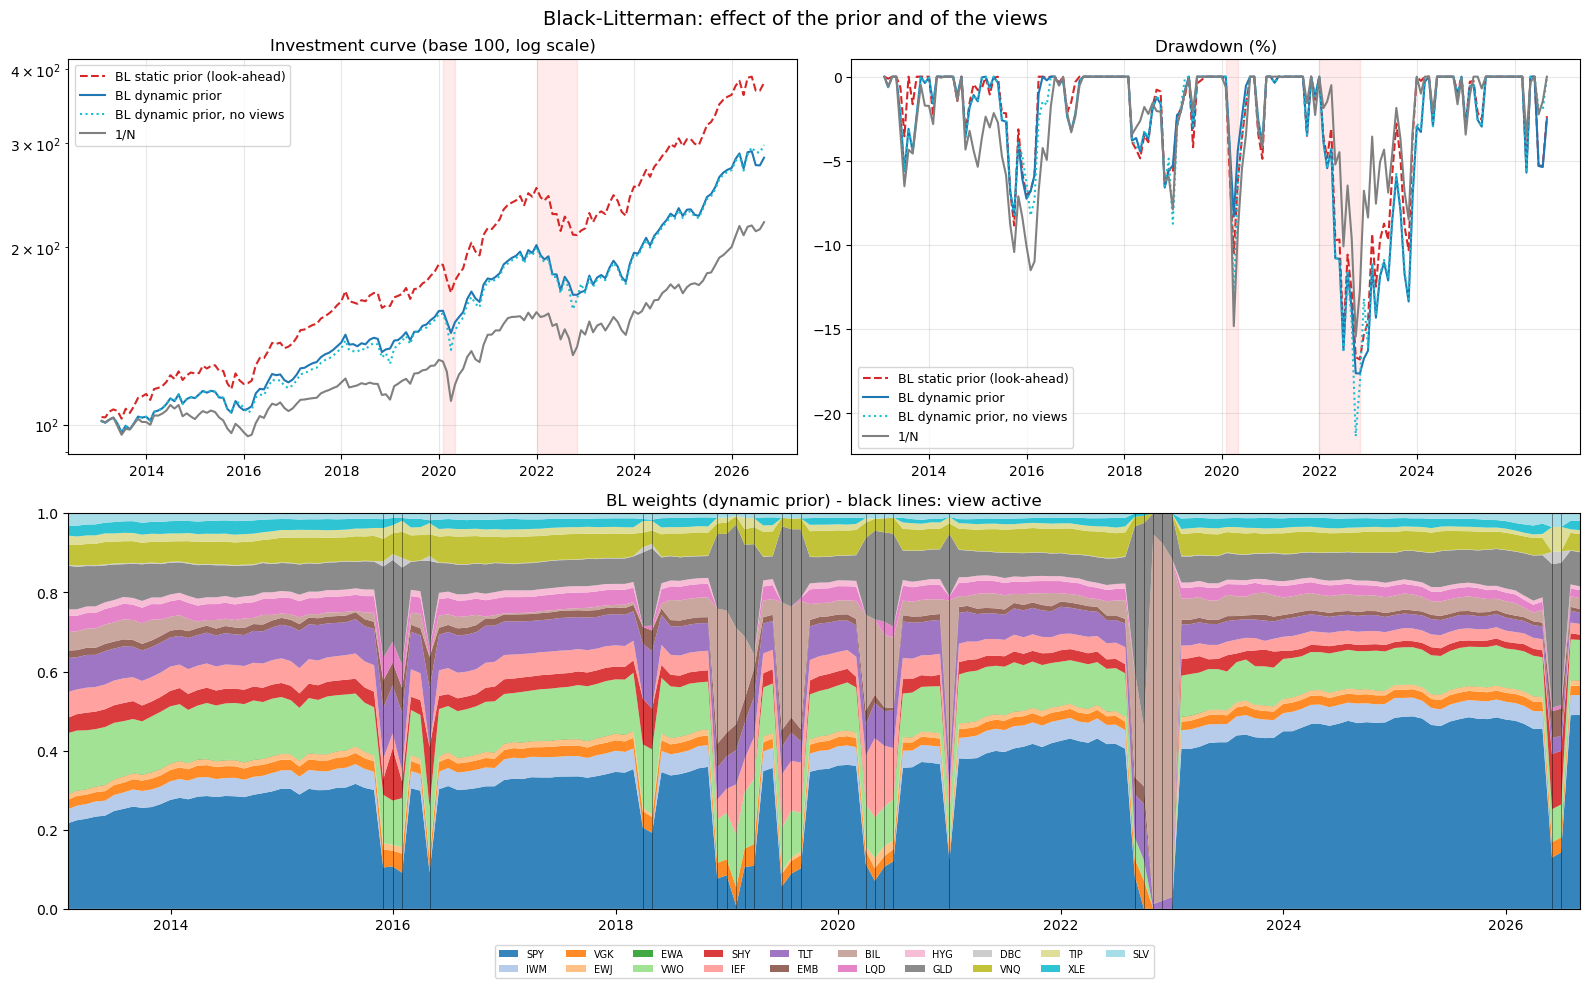

In [ ]:
# Black-Litterman summary chart
series = {
    "BL static prior (look-ahead)": ("Black-Litterman", "tab:red", "--"),
    "BL dynamic prior": ("BL-DynPrior", "tab:blue", "-"),
    "BL dynamic prior, no views": ("BL-DynPrior-NoView", "tab:cyan", ":"),
    "1/N": ("1/N", "grey", "-"),
}
crises = [("2020-02-01", "2020-04-30"), ("2022-01-01", "2022-10-31")]

# months with the view active
view_on = pd.Series([build_view(returns.iloc[i-WINDOW+1:i+1], assets)[0] is not None
                     for i in range(WINDOW-1, len(dates)-1)], index=rebal_dates)

fig = plt.figure(figsize=(16, 10))
ax1 = plt.subplot(2, 2, 1)
ax2 = plt.subplot(2, 2, 2)
ax3 = plt.subplot(2, 1, 2)

# investment curve
for label, (col, c, ls) in series.items():
    ax1.plot(bt.index, (1 + bt[col]).cumprod() * 100, color=c, ls=ls, label=label)
ax1.set_yscale("log")
ax1.set_title("Investment curve (base 100, log scale)")

# drawdown
for label, (col, c, ls) in series.items():
    wealth = (1 + bt[col]).cumprod()
    ax2.plot(bt.index, (wealth / wealth.cummax() - 1) * 100, color=c, ls=ls, label=label)
ax2.set_title("Drawdown (%)")

for a in (ax1, ax2):
    for s, e in crises:
        a.axvspan(pd.Timestamp(s), pd.Timestamp(e), color="red", alpha=0.08)
    a.legend(fontsize=9)
    a.grid(alpha=0.3)

# BL weights (dynamic prior), same colours as the other weight maps; black lines = view active
W = pd.DataFrame(weights_hist["BL-DynPrior"], index=rebal_dates, columns=assets)
ax3.stackplot(W.index, W.T.values, labels=assets,
              colors=plt.cm.tab20(np.linspace(0, 1, len(assets))), alpha=0.9)
for d in view_on[view_on].index:
    ax3.axvline(d, color="black", lw=0.6, alpha=0.5)
ax3.set_ylim(0, 1)
ax3.set_xlim(W.index.min(), W.index.max())
ax3.set_title("BL weights (dynamic prior) - black lines: view active")
ax3.legend(fontsize=7, ncol=10, loc="upper center", bbox_to_anchor=(0.5, -0.08))

plt.suptitle("Black-Litterman: effect of the prior and of the views", fontsize=14)
plt.tight_layout()
plt.show()

The chart makes visible what emerged from the previous table. In the investment curve, the static-prior version grows consistently above the dynamic-prior one: the gap between the two is the effect of the look-ahead. The two dynamic versions, with and without views, stay very close for most of the period, while 1/N remains below both.

The drawdown panel shows where the view makes a difference. The curves separate mainly in stressed phases, most clearly in 2022, when equities and bonds fell together: without views the loss is deeper.

The weight map shows how the dynamic prior evolves. SPY's weight starts low and grows over time with its market value, instead of being fixed at today's level from the first month. In the months marked by the black lines the equity weight drops sharply and the allocation shifts toward GLD and BIL, the defensive side of the view, then returns to the equilibrium mix once the signal switches off.

## Final comparison

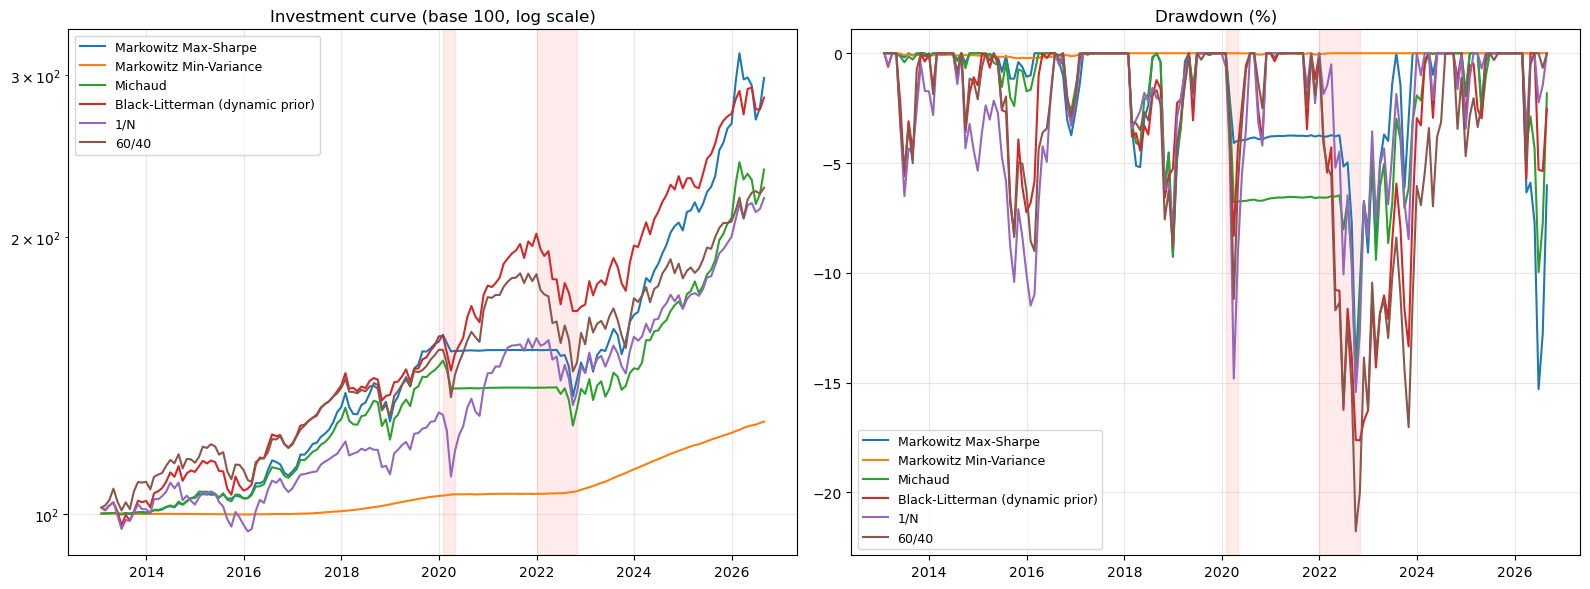

In [ ]:
# Final comparison: BL with dynamic prior, Markowitz, Michaud, benchmarks
# column name -> label shown in charts and tables (reused in the next cells)
final = {
    "Max-Sharpe": "Markowitz Max-Sharpe",
    "Min-Variance": "Markowitz Min-Variance",
    "Michaud": "Michaud",
    "BL-DynPrior": "Black-Litterman (dynamic prior)",
    "1/N": "1/N",
    "60/40": "60/40",
}
crises = [("2020-02-01", "2020-04-30"), ("2022-01-01", "2022-10-31")]

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

for col, label in final.items():
    wealth = (1 + bt[col]).cumprod()
    ax[0].plot(bt.index, wealth * 100, label=label)
    ax[1].plot(bt.index, (wealth / wealth.cummax() - 1) * 100, label=label)

ax[0].set_yscale("log")
ax[0].set_title("Investment curve (base 100, log scale)")
ax[1].set_title("Drawdown (%)")

for a in ax:
    for s, e in crises:
        a.axvspan(pd.Timestamp(s), pd.Timestamp(e), color="red", alpha=0.08)
    a.legend(fontsize=9)
    a.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The chart compares all the strategies, with Black-Litterman in its version with the dynamic prior. At the end of the period, Max-Sharpe and Black-Litterman obtain the highest values, followed by Michaud and by the two benchmarks, while Min-Variance remains close to its initial value for the entire sample.

The trajectories, however, are very different. Max-Sharpe and Michaud present long constant phases, especially between 2020 and 2022, when they are invested almost only in the cash proxy: in the drawdown panel their lines remain constant below zero, without further losses and without recovery. Max-Sharpe constructs the major part of its final advantage after 2022. Black-Litterman, on the contrary, remains invested and increases in a regular manner for the entire period, but in the 2022 crisis it registers a more profound drawdown.

The drawdown panel also evidences the limit of the 60/40 portfolio: its maximum loss is in 2022, when equities and bonds decreased simultaneously and the bond component offered no protection. Min-Variance presents practically no drawdown, because it coincides with the cash proxy.

Cumulative return in the 2022 window (%):
Equities (60/40 equity leg)         -20.53
Government bonds (60/40 bond leg)   -19.30
dtype: float64


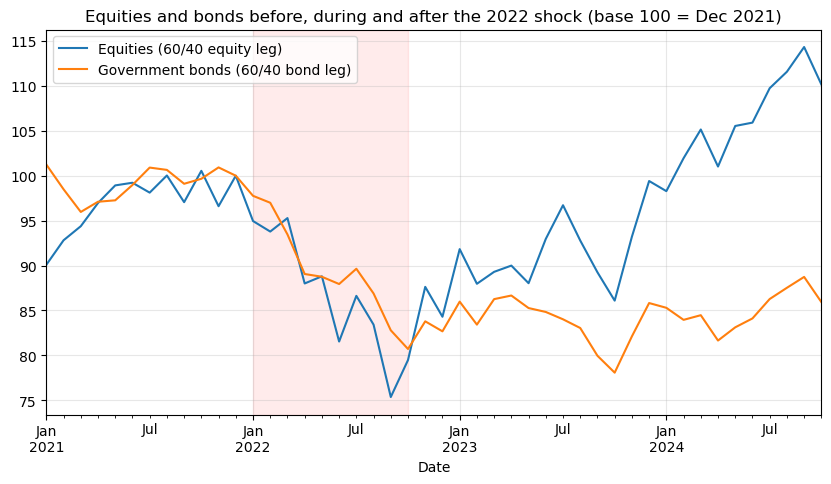

In [ ]:
# Equity leg vs bond leg of the 60/40, before, during and after the 2022 shock
period = returns_simple.loc["2021-01-01":"2024-10-31"]
legs = pd.DataFrame({
    "Equities (60/40 equity leg)": period[equity].mean(axis=1),
    "Government bonds (60/40 bond leg)": period[govt].mean(axis=1),
})

print("Cumulative return in the 2022 window (%):")
print(((1 + legs.loc["2022-01-01":"2022-10-31"]).prod() - 1).mul(100).round(2))

wealth = (1 + legs).cumprod()
wealth = wealth / wealth.loc["2021-12-31"] * 100   # rebased: 100 at the start of the 2022 window
ax = wealth.plot(figsize=(10, 5), title="Equities and bonds before, during and after the 2022 shock (base 100 = Dec 2021)")
ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-10-31"), color="red", alpha=0.08)
plt.grid(alpha=0.3)
plt.show()

The chart compares the two components of the 60/40 portfolio, the equity basket and the government bond basket, each with equal weights within it. Both series are rebased to 100 in December 2021, the month before the start of the crisis: each point therefore indicates the value relative to that moment.

In 2021 the two components behave differently: equities increase in a regular manner, while bonds remain substantially stable. In the 2022 window (highlighted area) the two lines decrease together for almost the entire period and at the end arrive at similar levels. There is no phase in which bonds increase to compensate for the decline of equities, as normally happens in crises: the rapid increase in interest rates hit both asset classes at the same moment. This explains why the 60/40 registers the most severe loss in the 2022 window.

After the crisis the behaviour separates again. Equities recover and in 2024 exceed the level of the end of 2021, while bonds remain well below it for the entire period observed. For a portfolio with an important bond component, therefore, the 2022 loss was not only temporary.

In [ ]:
# months with the view active (same for static and dynamic prior)
print(f"View active in {view_on.sum()} months out of {len(view_on)}")
print(view_on[view_on].index.year.value_counts().sort_index())

View active in 26 months out of 164
2015    2
2016    2
2018    4
2019    6
2020    5
2022    5
2026    2
Name: count, dtype: int64


The weight maps show that the defensive allocation appears only occasionally, not as a permanent change in the portfolio. This is consistent with the table: the view is active in 26 of the 164 months, about 16% of the sample. This is intentional. A signal constructed specifically for the 2020 and 2022 crises would use information not available at the time, and would introduce a look-ahead bias. The model instead uses a general signal based on volatility, which becomes active every time recent volatility increases significantly, independently of what happens after.

The distribution by calendar year confirms this. The view is active in 5 months in 2020 and in 5 months in 2022, the years of the two crises, but also in other years of elevated volatility, especially 2018 and 2019 (10 months in total), and occasionally in 2015, 2016 and 2026. This is expected: the signal observes only volatility, and cannot know in advance which episodes will become major crises.

### Turnover

In [ ]:
TC = 0.0010   # proportional cost per side: 10 bps

turn_hist, net_hist = {}, {}
r_simple_mat = returns_simple.reindex(rebal_dates).values   # realised returns in the holding months

for s in strategies:
    W = np.asarray(weights_hist[s])   # target weights at each rebalancing (T, n)
    gross = bt[s].values              # realised gross returns (T,)
    T, nA = W.shape

    turn = np.zeros(T)
    cost = np.zeros(T)
    w_drift = np.zeros(nA)

    for k in range(T):
        traded = np.abs(W[k] - w_drift).sum()   # trade needed, net of weight drift
        turn[k] = 0.5 * traded
        cost[k] = TC * traded
        w_drift = W[k] * (1 + r_simple_mat[k]) / (1 + gross[k])

    turn_hist[s] = pd.Series(turn, index=rebal_dates)
    net_hist[s] = pd.Series(gross - cost, index=rebal_dates)

net_bt = pd.DataFrame(net_hist)

# final comparison, BL with dynamic prior
final = {
    "Max-Sharpe": "Markowitz Max-Sharpe",
    "Min-Variance": "Markowitz Min-Variance",
    "Michaud": "Michaud",
    "BL-DynPrior": "Black-Litterman (dynamic prior)",
    "1/N": "1/N",
    "60/40": "60/40",
}
net_table = net_bt[list(final)].apply(perf_stats).T
net_table["Turnover %/mo"] = [turn_hist[s].mean() * 100 for s in final]
net_table.index = list(final.values())

print(f"Net-of-cost performance (TC = {TC * 1e4:.0f} bps per side)\n")
print(net_table.round(2))

Net-of-cost performance (TC = 10 bps per side)

                                 CAGR %  Vol %  Sharpe  MaxDD %  Turnover %/mo
Markowitz Max-Sharpe               8.06   8.50    0.75   -15.37           9.48
Markowitz Min-Variance             1.68   0.58   -0.19    -0.26           0.73
Michaud                            6.21   7.50    0.60   -15.49          11.80
Black-Litterman (dynamic prior)    7.73   9.05    0.67   -17.91           7.28
1/N                                5.91   9.00    0.49   -15.46           1.56
60/40                              6.12   9.37    0.49   -21.80           1.42


With a cost of 10 basis points per side, the impact of costs is contained. The Sharpe ratio decreases by a few hundredths for all active strategies (Max-Sharpe from 0.77 to 0.75, Black-Litterman from 0.69 to 0.67, Michaud from 0.64 to 0.60) and the CAGR by about a quarter of a point. The ranking does not change: Max-Sharpe remains first, followed by Black-Litterman and Michaud, and all three remain above the two benchmarks (0.49).

Turnover is more informative than costs, because it shows how each model operates. The benchmarks have a minimal turnover (1.56% and 1.42% per month), due only to rebalancing toward fixed weights. Min-Variance, always invested in BIL, has almost nothing to exchange (0.73%). Michaud has the highest turnover of all strategies (11.8% per month), although it is the most diversified in normal periods. A possible explanation is precisely diversification: the average portfolio distributes the weights over many assets, and each of these weights moves from one month to the next; to this are added the complete transitions into and out of BIL. Diversification, therefore, does not mean stability. Max-Sharpe (9.48%) is concentrated, but changes composition abruptly from one phase to another. Black-Litterman has the lowest turnover among the three models (7.28%): its equilibrium core remains stable, and the exchanges concentrate in the months when the view is activated or deactivated.

In [ ]:
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)

# Annual returns and crisis windows, final strategies (BL with dynamic prior)
# uses the final dictionary defined in the final comparison chartb = bt[list(final)].rename(columns=final)
b = bt[list(final)].rename(columns=final)
annual = (1 + b).groupby(b.index.year).prod() - 1
print("Return per calendar year (%):\n")
print((annual * 100).round(1))

crises = {
    "Covid crash (2020-02 -> 2020-04)": ("2020-02-01", "2020-04-30"),
    "2022 shock (2022-01 -> 2022-10)": ("2022-01-01", "2022-10-31"),
}
rows = {name: ((1 + b.loc[s:e]).prod() - 1) * 100 for name, (s, e) in crises.items()}
print("\nCumulative return in crisis windows (%):\n")
print(pd.DataFrame(rows).T.round(2))

Return per calendar year (%):

      Markowitz Max-Sharpe  Markowitz Min-Variance  Michaud  Black-Litterman (dynamic prior)   1/N  60/40
2013                   0.3                    -0.1      0.1                              3.2   1.1    8.3
2014                   3.7                     0.0      4.2                              7.5   1.2    4.9
2015                  -0.1                    -0.1     -0.5                             -4.6  -5.0   -1.8
2016                   7.0                     0.1      6.4                             12.6   9.7    6.7
2017                  17.5                     0.7     14.6                             15.6  10.7   15.2
2018                  -3.6                     1.7     -5.0                             -2.3  -6.5   -6.8
2019                  22.1                     2.1     20.3                             15.7  16.8   18.1
2020                  -2.1                     0.5     -5.3                             13.5  10.3   14.1
2021           

## Answer to the research question 

The question was which approach offers the most robust allocation in the difficult years after 2020, and to what extent the models beat the 1/N and 60/40 benchmarks. The answer does not indicate an absolute winner, but clarifies what makes each model robust, or fragile.

**The crises.** In the Covid crash, Max-Sharpe (−3.98%) and Black-Litterman (−4.39%) lose less than Michaud (−6.75%) and the two benchmarks (−6.04% for the 60/40, −8.64% for 1/N). In the 2022 shock the ranking is inverted: Michaud (−5.02%) and Max-Sharpe (−7.07%) lose little, while Black-Litterman loses 17.63%, almost as much as the 60/40 (−19.83%). Looking only at the crisis windows, Max-Sharpe and Michaud would appear to be the most defensive models.

**Why this reading is misleading.** The protection of Max-Sharpe and Michaud in 2022 does not originate from an evaluation of risk, but from the estimation error analysed previously: after the rate cuts of 2020 both concentrated on BIL, and remained there until the end of 2022. The same position that protected them in 2022 kept them out of the market in 2020 and 2021: in those two years Max-Sharpe obtains −2.1% and 0.0%, Michaud −5.3% and 0.0%, while Black-Litterman gains 13.5% and 13.9%. It is an accidental protection, which depends on the path of interest rates and would not repeat in a crisis with different conditions. Also the final advantage of Max-Sharpe over the entire sample (Sharpe 0.77) is constructed largely in 2023–2025, when high rates made BIL unattractive and the optimiser returned to the risky assets.

**Black-Litterman.** Black-Litterman is the model with the most coherent behaviour: it remains invested for the entire cycle, it is not affected by the distortion of BIL, and it changes allocation only when the view requires it. Its weak point is 2022. The view is activated, but it is not sufficient: the prior remains anchored to a market portfolio with a strong equity component, and in a long and gradual decline the volatility signal, which compares the last 3 months with the last 60, is activated less often than in a sudden crash like that of 2020. Its result also depends on the prior: with the static prior, contaminated by look-ahead, the Sharpe ratio arrived at 0.86; with the dynamic prior it is 0.69.

**The benchmarks.** Over the entire sample all three optimised models exceed both benchmarks in Sharpe ratio (0.77, 0.69 and 0.64 against 0.49 and 0.50), also net of costs. Min-Variance is the exception, because it coincides with the cash proxy. The 60/40 is the worst portfolio in 2022: equities and bonds decreased together, and its defensive component offered no protection. The 1/N loses less than the 60/40 in 2022 (−12.68%), because it distributes capital also over asset classes different from equities and nominal bonds.

**In synthesis.** Max-Sharpe obtains the best result over the entire sample, but it is the least robust: concentrated, unstable, and dependent on estimation errors that in this sample proved favourable. Michaud reduces concentration in normal periods, but does not correct the same errors when they are systematic. Black-Litterman is the most stable and the only one immune to the distortion of cash, but it protects only partially in slow crises like 2022. With only two crisis episodes, these conclusions describe a mechanism, not a statistically demonstrated result.

## Critical analysis

The project presents some limits.

The most evident is that the conclusions on the crises are based on only two episodes, 2020 and 2022. They show how the models behave, but they are not sufficient to affirm that they would behave in the same way in other crises.

A second limit concerns BIL. The cash proxy is included among the optimised assets, and this choice produces non-negligible effects: Min-Variance practically coincides with BIL, and Max-Sharpe and Michaud concentrate on cash when its historical average exceeds the risk-free rate. Excluding cash from the optimisation would make the comparison cleaner.

Some methodological choices are also simple and could be improved. The covariance is estimated only with the sample estimator, which is not very stable with 19 assets and 60 months, and no limit is imposed on the weight of each asset, so Max-Sharpe is very concentrated. It is not verified whether the differences between the Sharpe ratios are statistically significant, and different values are not tested for the estimation window, the costs or the parameters of the view.

The dynamic prior of Black-Litterman is also an approximation: it assumes that the number of shares of the ETFs remained constant over time, which in reality is not true.

Finally, since the universe starts at the end of 2007, the 2008 crisis enters only the first estimation window and is never evaluated out of sample.

## Future developments
The work can be extended in several directions, starting from the limits highlighted.

The treatment of cash could be modified by excluding BIL from the optimisation and using it only as a riskless asset, combined with the optimal portfolio through a constraint on volatility. In this way the distortion observed for Max-Sharpe and Michaud would be avoided.

The estimation of the parameters could be made more stable with a shrinkage estimator of the covariance (Ledoit-Wolf) and with a limit on the weight of each asset, for example 35%, to reduce concentration. It would also be useful to verify the statistical significance of the differences between the Sharpe ratios and to repeat the analysis with different values for the estimation window, the costs and the parameters of the view.

For Black-Litterman, the view could be constructed by weighting the assets by capitalisation, as suggested by Idzorek (2004), and its uncertainty could be fixed with the method of the same author, which translates into Ω a confidence level expressed between 0% and 100%. The signal could also be based on a measure different from volatility, for example the correlation between equities and bonds, to react better to slow crises like that of 2022. Finally, the prior could use real historical capitalisations by asset class, instead of reconstructing them from prices.

A more innovative extension consists in generating the views with a large language model (LLM), queried through an API at each rebalancing date. The idea is coherent with Black-Litterman, in which the views are by definition subjective and can come from any source. It presents, however, an important problem for the backtest: a model trained on data covering the period analysed already knows what happened, and its views would therefore be contaminated by future information. To reduce this risk, the model could be given only anonymous numerical data, without dates or asset names; more rigorously, the strategy should be evaluated only on data subsequent to the training date of the model. It would also remain to define how to translate the confidence declared by the model into the matrix Ω, for example with the method of Idzorek.

## Bibliography 

Black, F., & Litterman, R. (1992). Global Portfolio Optimization. Financial Analysts Journal, 48(5), 28–43.

DeMiguel, V., Garlappi, L., & Uppal, R. (2009). Optimal Versus Naive Diversification: How Inefficient is the 1/N Portfolio Strategy? The Review of Financial Studies, 22(5), 1915–1953.

Drobetz, W. (2001). How to Avoid the Pitfalls in Portfolio Optimization? Putting the Black-Litterman Approach at Work. Financial Markets and Portfolio Management, 15(1), 59–75.

He, G., & Litterman, R. (1999). The Intuition Behind Black-Litterman Model Portfolios. Goldman Sachs Investment Management Research.

Idzorek, T. M. (2004). A Step-by-Step Guide to the Black-Litterman Model: Incorporating User-Specified Confidence Levels. Working paper, Zephyr Associates.

Ledoit, O., & Wolf, M. (2004). A Well-Conditioned Estimator for Large-Dimensional Covariance Matrices. Journal of Multivariate Analysis, 88(2), 365–411.

Markowitz, H. (1952). Portfolio Selection. The Journal of Finance, 7(1), 77–91.

Michaud, R. O. (1989). The Markowitz Optimization Enigma: Is 'Optimized' Optimal? Financial Analysts Journal, 45(1), 31–42.

Michaud, Richard O., & Michaud, Robert O. (2008). Estimation Error and Portfolio Optimization: A Resampling Solution. Journal of Investment Management, 6(1), 8–28.

Sharpe, W. F. (1964). Capital Asset Prices: A Theory of Market Equilibrium under Conditions of Risk. The Journal of Finance, 19(3), 425–442.

Tobin, J. (1958). Liquidity Preference as Behavior Towards Risk. The Review of Economic Studies, 25(2), 65–86.

Zhao, F. (2023). Portfolio Construction using Black-Litterman Model and Factors. arXiv:2311.04475.

Lee, Y., Kim, Y., Kim, J., Kim, S., & Lee, Y. (2025). LLM-Enhanced Black-Litterman Portfolio Optimization. arXiv:2504.14345.

*AI disclaimer: AI was used in this project to develop more efficient code and to write comments and portions of text in rigorous academic English.